# Language Proficiency Evaluation — Rater Reliability Analysis

**Dataset:** 90 student evaluators × 8 speech recordings × 3 criteria  
**Criteria (Czech):**
- `Srozumitelnost` — Intelligibility
- `Přízvuk` — Accent / Pronunciation
- `Čeština` — Czech language quality

**Scale:** 1–10 (10 = best)

**Research questions:**
1. Which student evaluators are reliable (consistent across recordings)?
2. Which criteria are correlated and reliable?
3. Do evaluators use different scoring ranges (severity bias)?
4. Should outlier evaluators or recordings be removed?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from scipy.stats import spearmanr, pearsonr
import warnings
warnings.filterwarnings('ignore')

# ── Aesthetics ──────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#f8f9fa',
    'axes.grid': True,
    'grid.color': 'white',
    'grid.linewidth': 0.8,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})
PALETTE = ['#4C72B0', '#DD8452', '#55A868']  # blue, orange, green
print('Libraries loaded successfully.')

Matplotlib is building the font cache; this may take a moment.


Libraries loaded successfully.


## 1. Load & reshape data

In [2]:
# ── Load raw TSV ────────────────────────────────────────────────
raw = pd.read_csv('students.tsv', sep='\t')
print(f'Raw shape: {raw.shape}  ({raw.shape[0]} raters × {raw.shape[1]} columns)')

# ── Parse column names → recording × criterion ─────────────────
records = []
for col in raw.columns:
    rec, crit = col.rsplit(' [', 1)
    crit = crit.rstrip(']')
    records.append({'column': col, 'recording': rec, 'criterion': crit})

col_meta = pd.DataFrame(records)

# Short readable recording IDs  e.g. "03-MH", "06-ET" …
def short_id(full):
    parts = full.replace('.xml', '').split('_')
    num   = parts[1]          # e.g. 03
    init  = full.split('-')[-1].replace('.xml','')   # e.g. MH
    return f'{num}-{init}'

col_meta['rec_id'] = col_meta['recording'].apply(short_id)

# Criterion English labels
CRIT_LABELS = {
    'Srozumitelnost': 'Intelligibility',
    'Přízvuk':        'Accent',
    'Čeština':        'Czech quality'
}
col_meta['crit_en'] = col_meta['criterion'].map(CRIT_LABELS)

print('\nRecordings:')
for rid, rlong in col_meta[['rec_id','recording']].drop_duplicates().values:
    print(f'  {rid:8s}  {rlong}')
print('\nCriteria:', col_meta['criterion'].unique().tolist())

# ── Melt to long format ─────────────────────────────────────────
raw.index.name = 'rater_id'
long = raw.reset_index().melt(
    id_vars='rater_id', var_name='column', value_name='score'
).merge(col_meta, on='column')

print(f'\nLong format shape: {long.shape}')
long.head()

Raw shape: (90, 24)  (90 raters × 24 columns)

Recordings:
  03-task2-from-MH  https://lindat.mff.cuni.cz/services/teitok-live/evaldio/cs/index.php?action=file&cid=xmlfiles/UJOP-A2-220919_03-task2-from_whisperX-MH.xml
  06-task2-from-ET  https://lindat.mff.cuni.cz/services/teitok-live/evaldio/cs/index.php?action=file&cid=xmlfiles/UJOP-A2-221205_06-task2-from_mixed-ET.xml
  05-task2-from-ET  https://lindat.mff.cuni.cz/services/teitok-live/evaldio/cs/index.php?action=file&cid=xmlfiles/UJOP-A2-221205_05-task2-from_mixed-ET.xml
  14-task2-from-ET  https://lindat.mff.cuni.cz/services/teitok-live/evaldio/cs/index.php?action=file&cid=xmlfiles/UJOP-A2-221205_14-task2-from_mixed-ET.xml
  08-task2-from-ZM  https://lindat.mff.cuni.cz/services/teitok-live/evaldio/cs/index.php?action=file&cid=xmlfiles/UJOP-A2-221205_08-task2-from_mixed-ZM.xml
  17-task2-from-AP  https://lindat.mff.cuni.cz/services/teitok-live/evaldio/cs/index.php?action=file&cid=xmlfiles/UJOP-A2-221205_17-task2-from_mixed-AP.xml
  

,rater_id,column,score,recording,criterion,rec_id,crit_en
0,0,https://lindat.mff.cuni.cz/services/teitok-liv...,10,https://lindat.mff.cuni.cz/services/teitok-liv...,Srozumitelnost,03-task2-from-MH,Intelligibility
1,1,https://lindat.mff.cuni.cz/services/teitok-liv...,6,https://lindat.mff.cuni.cz/services/teitok-liv...,Srozumitelnost,03-task2-from-MH,Intelligibility
2,2,https://lindat.mff.cuni.cz/services/teitok-liv...,4,https://lindat.mff.cuni.cz/services/teitok-liv...,Srozumitelnost,03-task2-from-MH,Intelligibility
3,3,https://lindat.mff.cuni.cz/services/teitok-liv...,4,https://lindat.mff.cuni.cz/services/teitok-liv...,Srozumitelnost,03-task2-from-MH,Intelligibility
4,4,https://lindat.mff.cuni.cz/services/teitok-liv...,6,https://lindat.mff.cuni.cz/services/teitok-liv...,Srozumitelnost,03-task2-from-MH,Intelligibility


## 2. Descriptive overview

In [3]:
print('=== Overall score distribution ===')
print(long['score'].describe().round(2))

print('\n=== Mean score per criterion ===')
print(long.groupby('criterion')['score'].describe().round(2))

print('\n=== Mean score per recording (all criteria) ===')
print(long.groupby('rec_id')['score'].agg(['mean','std','min','max']).round(2))

=== Overall score distribution ===
count    2160.00
mean        5.20
std         2.06
min         1.00
25%         4.00
50%         5.00
75%         7.00
max        10.00
Name: score, dtype: float64

=== Mean score per criterion ===
                count  mean   std  min  25%  50%  75%   max
criterion                                                  
Přízvuk         720.0  4.82  1.95  1.0  3.0  5.0  6.0  10.0
Srozumitelnost  720.0  5.68  2.11  1.0  4.0  6.0  7.0  10.0
Čeština         720.0  5.09  2.02  1.0  4.0  5.0  7.0  10.0

=== Mean score per recording (all criteria) ===
                  mean   std  min  max
rec_id                                
03-task2-from-MH  5.53  1.92    1   10
04-task2-from-KV  4.80  1.94    1   10
05-task2-from-ET  4.97  1.72    1    9
06-task2-from-ET  3.76  1.65    1   10
08-task2-from-ZM  4.44  1.78    1   10
09-task2-from-ET  6.60  2.02    1   10
14-task2-from-ET  6.04  2.10    1   10
17-task2-from-AP  5.41  1.89    2   10


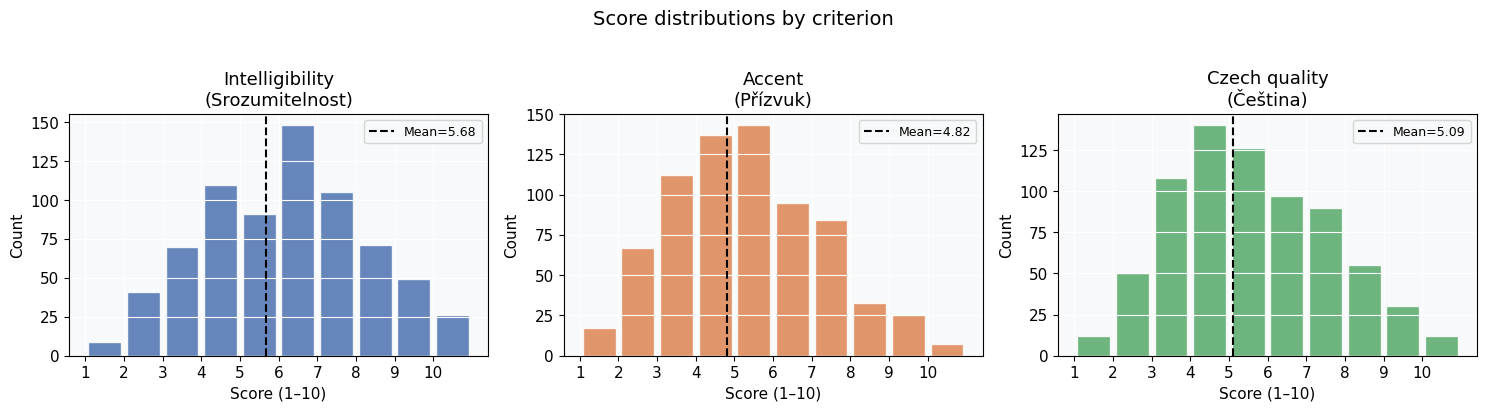

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
fig.suptitle('Score distributions by criterion', fontsize=14, y=1.02)

for ax, (crit, crit_en), color in zip(axes, CRIT_LABELS.items(), PALETTE):
    data = long[long['criterion'] == crit]['score']
    ax.hist(data, bins=range(1, 12), color=color, edgecolor='white', alpha=0.85, rwidth=0.85)
    ax.axvline(data.mean(), color='black', lw=1.5, ls='--', label=f'Mean={data.mean():.2f}')
    ax.set_title(f'{crit_en}\n({crit})')
    ax.set_xlabel('Score (1–10)')
    ax.set_ylabel('Count')
    ax.set_xticks(range(1, 11))
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('fig1_score_distributions.png', dpi=130, bbox_inches='tight')
plt.show()

## 3. Inter-rater reliability — ICC and Krippendorff's alpha

We compute **ICC(2,1)** (two-way random, single measures) for absolute agreement and **ICC(3,1)** (two-way mixed-effects, consistency, single measures), treating the observed raters as fixed. ICC(3,1) ignores systematic differences in raters' score levels, unlike ICC(2,1). Since the 1–10 score scale is ordinal, we also report **Krippendorff's alpha with ordinal distance**, which treats scores as ordered categories and accommodates missing ratings.

> *ICC(2,1) = (MS_subject − MS_error) / (MS_subject + (k−1)·MS_error + k/n·(MS_rater − MS_error))*  
> *ICC(3,1) = (MS_subject − MS_error) / (MS_subject + (k−1)·MS_error)*

ICC benchmarks (Koo & Mae, 2016):  
< 0.50 = poor | 0.50–0.75 = moderate | 0.75–0.90 = good | > 0.90 = excellent

In [5]:
def icc_twoway_random(data_matrix):
    """
    Compute ICC(2,1) — two-way random effects, absolute agreement, single measures.
    data_matrix: shape (n_subjects, k_raters)
    Returns ICC(2,1), ICC(3,1), F, degrees of freedom, p-value, and ICC(2,1) CI.
    """
    X = np.array(data_matrix, dtype=float)
    n, k = X.shape                          # subjects, raters

    grand_mean = X.mean()
    subject_means = X.mean(axis=1)
    rater_means   = X.mean(axis=0)

    SS_between = k * np.sum((subject_means - grand_mean)**2)
    SS_rater   = n * np.sum((rater_means   - grand_mean)**2)
    SS_total   = np.sum((X - grand_mean)**2)
    SS_error   = SS_total - SS_between - SS_rater

    df_between = n - 1
    df_rater   = k - 1
    df_error   = (n - 1) * (k - 1)

    MS_between = SS_between / df_between
    MS_rater   = SS_rater   / df_rater
    MS_error   = SS_error   / df_error

    icc = (MS_between - MS_error) / (
        MS_between + (k - 1) * MS_error + (k / n) * (MS_rater - MS_error)
    )
    icc_3_1 = (MS_between - MS_error) / (
        MS_between + (k - 1) * MS_error
    )

    # F-statistic and p-value for subjects
    F   = MS_between / MS_error
    p   = 1 - stats.f.cdf(F, df_between, df_error)

    # 95% CI via F-distribution
    alpha = 0.05
    FL    = F / stats.f.ppf(1 - alpha/2, df_between, df_error)
    FU    = F * stats.f.ppf(1 - alpha/2, df_error,   df_between)
    L     = (FL - 1) / (FL + k - 1)
    U     = (FU - 1) / (FU + k - 1)

    return dict(icc=round(icc, 4), icc_3_1=round(icc_3_1, 4), F=round(F, 3),
                df1=df_between, df2=df_error,
                p=round(p, 4), ci_low=round(L, 4), ci_high=round(U, 4))


print('ICC(2,1) absolute agreement vs ICC(3,1) consistency — per criterion')
print('-'*82)
icc_results = {}
for crit, crit_en in CRIT_LABELS.items():
    # pivot: rows=recordings, cols=raters
    pivot = long[long['criterion'] == crit].pivot_table(
        index='rec_id', columns='rater_id', values='score'
    )
    res = icc_twoway_random(pivot.values)
    icc_results[crit] = res
    bench = ('poor' if res['icc'] < .50 else
             'moderate' if res['icc'] < .75 else
             'good' if res['icc'] < .90 else 'excellent')
    delta = res['icc_3_1'] - res['icc']
    print(f'{crit_en:20s} ICC(2,1)={res["icc"]:.3f}  ICC(3,1)={res["icc_3_1"]:.3f}  '
          f'Δ(3,1−2,1)={delta:+.3f}  95%CI(2,1) [{res["ci_low"]:.3f},{res["ci_high"]:.3f}]  '
          f'F({res["df1"]},{res["df2"]})={res["F"]:.2f}  p={res["p"]:.4f}  → {bench}')

print('\nNote: these ICCs treat recordings as the unit being measured and raters as the measurement instrument.')

ICC(2,1) per criterion — raters as columns, recordings as rows
-----------------------------------------------------------------
Intelligibility      ICC=0.219  95%CI [0.179,0.687]  F(7,623)=47.72  p=0.0000  → poor
Accent               ICC=0.111  95%CI [0.081,0.484]  F(7,623)=20.56  p=0.0000  → poor
Czech quality        ICC=0.254  95%CI [0.197,0.709]  F(7,623)=53.11  p=0.0000  → poor

Note: these ICCs treat recordings as the unit being measured and raters as the measurement instrument.


In [ ]:
import krippendorff

print("Krippendorff's alpha (ordinal) per criterion — raters as rows, recordings as columns")
print('-'*82)
alpha_results = {}
for crit, crit_en in CRIT_LABELS.items():
    reliability_data = long[long['criterion'] == crit].pivot_table(
        index='rater_id', columns='rec_id', values='score'
    ).values
    alpha = krippendorff.alpha(
        reliability_data=reliability_data,
        level_of_measurement='ordinal'
    )
    alpha_results[crit] = alpha
    print(f'{crit_en:20s} α={alpha:.3f}')

print('\nNote: each column is a recording; missing ratings are handled as NaN.')

## 4. Per-rater reliability — consistency profile

In [ ]:
# For each rater: compute correlation with group mean across recordings, per criterion
# A reliable rater should rank recordings similarly to the group consensus.

# Group mean per recording × criterion
group_mean = long.groupby(['rec_id','criterion'])['score'].mean().reset_index(name='group_mean')

rater_stats = []
for rater_id in range(len(raw)):
    rater_data = long[long['rater_id'] == rater_id]
    merged = rater_data.merge(group_mean, on=['rec_id','criterion'])

    # Spearman correlation with group mean
    rho, pval = spearmanr(merged['score'], merged['group_mean'])

    # Personal mean and std
    pmean = rater_data['score'].mean()
    pstd  = rater_data['score'].std()
    pmin  = rater_data['score'].min()
    pmax  = rater_data['score'].max()
    prange = pmax - pmin

    rater_stats.append(dict(
        rater_id=rater_id,
        rho_vs_group=round(rho, 3),
        p_rho=round(pval, 4),
        mean=round(pmean, 2),
        std=round(pstd, 2),
        range=prange,
        min_score=pmin,
        max_score=pmax
    ))

rater_df = pd.DataFrame(rater_stats)
print('Per-rater statistics — first 15 rows')
print(rater_df.head(15).to_string(index=False))
print(f'\nTotal raters: {len(rater_df)}')

In [ ]:
# Flag unreliable raters: rho < 0.30 (weak agreement with consensus)
LOW_RHO  = 0.30
LOW_RANGE = 3   # used fewer than 3 distinct values

rater_df['flag_low_consistency'] = rater_df['rho_vs_group'] < LOW_RHO
rater_df['flag_low_range']       = rater_df['range'] < LOW_RANGE
rater_df['flagged']              = rater_df['flag_low_consistency'] | rater_df['flag_low_range']

print(f'Raters with low consistency (ρ < {LOW_RHO}): {rater_df["flag_low_consistency"].sum()}')
print(f'Raters with low range (< {LOW_RANGE} pts used): {rater_df["flag_low_range"].sum()}')
print(f'Total flagged raters: {rater_df["flagged"].sum()}')

print('\nFlagged rater details:')
flagged_cols = ['rater_id','rho_vs_group','p_rho','mean','std','range','flag_low_consistency','flag_low_range']
print(rater_df[rater_df['flagged']][flagged_cols].to_string(index=False))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Per-rater reliability profiles', fontsize=14)

# ─ Left: histogram of ρ ─────────────────────────────────────────
ax = axes[0]
ax.hist(rater_df['rho_vs_group'], bins=20, color='#4C72B0', edgecolor='white', alpha=0.85)
ax.axvline(LOW_RHO, color='red', lw=1.5, ls='--', label=f'Threshold (ρ={LOW_RHO})')
ax.axvline(rater_df['rho_vs_group'].mean(), color='black', lw=1.5, ls='-',
           label=f'Mean={rater_df["rho_vs_group"].mean():.2f}')
ax.set_xlabel('Spearman ρ vs. group consensus')
ax.set_ylabel('Number of raters')
ax.set_title('Rater–consensus correlation distribution')
ax.legend()

# ─ Right: scatter ρ vs scoring range ────────────────────────────
ax = axes[1]
colors = rater_df['flagged'].map({True: 'red', False: '#4C72B0'})
ax.scatter(rater_df['range'], rater_df['rho_vs_group'],
           c=colors, alpha=0.7, edgecolors='white', linewidths=0.5, s=50)
ax.axhline(LOW_RHO,  color='red', lw=1, ls='--', alpha=0.6)
ax.axvline(LOW_RANGE, color='orange', lw=1, ls='--', alpha=0.6)
ax.set_xlabel('Score range used by rater (max − min)')
ax.set_ylabel('Spearman ρ vs. group consensus')
ax.set_title('Consistency vs. range used\n(red = flagged)')
# Annotate flagged raters
for _, row in rater_df[rater_df['flagged']].iterrows():
    ax.annotate(f'#{int(row.rater_id)}', (row['range'], row['rho_vs_group']),
                textcoords='offset points', xytext=(4, 4), fontsize=8, color='red')

plt.tight_layout()
plt.savefig('fig2_rater_reliability.png', dpi=130, bbox_inches='tight')
plt.show()

## 5. Criterion correlations and reliability

In [ ]:
# Pivot to wide: one row per (rater, recording), columns = 3 criteria
wide = long.pivot_table(
    index=['rater_id', 'rec_id'], columns='criterion', values='score'
).reset_index()

crit_cols = list(CRIT_LABELS.keys())
crit_en_cols = [CRIT_LABELS[c] for c in crit_cols]

print('Pearson correlations between criteria (all rater-recording pairs):')
corr_matrix = wide[crit_cols].rename(columns=CRIT_LABELS).corr()
print(corr_matrix.round(3))

print('\nSpearman correlations:')
spearman_matrix = wide[crit_cols].rename(columns=CRIT_LABELS).corr(method='spearman')
print(spearman_matrix.round(3))

# Pairwise significance tests
print('\nPairwise Pearson r with p-values:')
for i, c1 in enumerate(crit_cols):
    for c2 in crit_cols[i+1:]:
        r, p = pearsonr(wide[c1].dropna(), wide[c2].dropna())
        print(f'  {CRIT_LABELS[c1]:20s} × {CRIT_LABELS[c2]:20s}  r={r:.3f}  p={p:.4g}')

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Criterion pairwise relationships (all rater × recording pairs)', fontsize=13)

pairs = [
    (crit_cols[0], crit_cols[1]),
    (crit_cols[0], crit_cols[2]),
    (crit_cols[1], crit_cols[2]),
]
for ax, (c1, c2) in zip(axes, pairs):
    x, y = wide[c1], wide[c2]
    r, p = pearsonr(x.dropna(), y.dropna())

    # Jitter for visibility
    jx = x + np.random.uniform(-0.2, 0.2, size=len(x))
    jy = y + np.random.uniform(-0.2, 0.2, size=len(y))
    ax.scatter(jx, jy, alpha=0.3, s=15, color='#4C72B0')

    # Regression line
    m, b = np.polyfit(x.dropna(), y.dropna(), 1)
    xline = np.linspace(1, 10, 50)
    ax.plot(xline, m*xline + b, color='red', lw=1.8, label=f'r={r:.2f}, p={p:.2e}')

    ax.set_xlabel(CRIT_LABELS[c1])
    ax.set_ylabel(CRIT_LABELS[c2])
    ax.set_title(f'{CRIT_LABELS[c1]} vs {CRIT_LABELS[c2]}')
    ax.legend(fontsize=9)
    ax.set_xlim(0.5, 10.5)
    ax.set_ylim(0.5, 10.5)

plt.tight_layout()
plt.savefig('fig3_criterion_correlations.png', dpi=130, bbox_inches='tight')
plt.show()

In [ ]:
# Heatmap of criterion correlations
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (method, mat) in zip(axes, [('Pearson', corr_matrix), ('Spearman', spearman_matrix)]):
    sns.heatmap(mat, annot=True, fmt='.3f', cmap='RdYlGn',
                vmin=-1, vmax=1, center=0, ax=ax,
                linewidths=0.5, cbar_kws={'shrink': 0.8})
    ax.set_title(f'{method} correlation\nbetween criteria')

plt.tight_layout()
plt.savefig('fig4_criterion_heatmap.png', dpi=130, bbox_inches='tight')
plt.show()

## 6. Evaluator range analysis — severity bias

In [ ]:
# Do raters differ in where they centre their scores?
# One-way ANOVA: are mean scores different across raters?
rater_groups = [group['score'].values for _, group in long.groupby('rater_id')]
F_stat, p_anova = stats.f_oneway(*rater_groups)
print(f'One-way ANOVA on rater means: F={F_stat:.2f}, p={p_anova:.4g}')

# Kruskal-Wallis (non-parametric alternative)
H_stat, p_kw = stats.kruskal(*rater_groups)
print(f'Kruskal–Wallis:               H={H_stat:.2f}, p={p_kw:.4g}')

print('\nRater mean score descriptives:')
print(rater_df[['rater_id','mean','std','range']].describe().round(2))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Evaluator scoring range and severity analysis', fontsize=14)

# ─ 1. Mean score distribution across raters ─────────────────────
ax = axes[0]
ax.hist(rater_df['mean'], bins=20, color='#55A868', edgecolor='white', alpha=0.85)
ax.axvline(rater_df['mean'].mean(), color='black', lw=1.5, ls='--',
           label=f'Grand mean={rater_df["mean"].mean():.2f}')
ax.set_xlabel('Rater mean score')
ax.set_ylabel('Count')
ax.set_title('Distribution of rater means\n(severity bias)')
ax.legend()

# ─ 2. Std deviation per rater ───────────────────────────────────
ax = axes[1]
ax.hist(rater_df['std'], bins=20, color='#DD8452', edgecolor='white', alpha=0.85)
ax.axvline(rater_df['std'].mean(), color='black', lw=1.5, ls='--',
           label=f'Mean SD={rater_df["std"].mean():.2f}')
ax.set_xlabel('Rater score SD')
ax.set_ylabel('Count')
ax.set_title('Distribution of rater SDs\n(spread used)')
ax.legend()

# ─ 3. Box-plot of individual rater means ────────────────────────
ax = axes[2]
# Sorted for readability
sorted_means = rater_df['mean'].sort_values()
colors_box = ['red' if rater_df.loc[rater_df['rater_id']==idx,'flagged'].values[0]
               else '#4C72B0' for idx in sorted_means.index]
bars = ax.barh(range(len(sorted_means)), sorted_means.values,
               color=colors_box, alpha=0.7, height=0.8)
ax.axvline(rater_df['mean'].mean(), color='black', lw=1.5, ls='--', alpha=0.7)
ax.set_xlabel('Mean score')
ax.set_ylabel('Rater (sorted)')
ax.set_title('Rater means sorted\n(red = flagged)')
ax.set_yticks([])

plt.tight_layout()
plt.savefig('fig5_rater_range_analysis.png', dpi=130, bbox_inches='tight')
plt.show()

# Outlier raters by mean (> 2 SD from grand mean)
grand_mean_all = rater_df['mean'].mean()
grand_std_all  = rater_df['mean'].std()
outlier_mean = rater_df[
    (rater_df['mean'] > grand_mean_all + 2*grand_std_all) |
    (rater_df['mean'] < grand_mean_all - 2*grand_std_all)
]
print(f'Raters with mean > 2 SD from grand mean ({grand_mean_all:.2f} ± {grand_std_all:.2f}):')
print(outlier_mean[['rater_id','mean','std','rho_vs_group']].to_string(index=False) if len(outlier_mean) else '  None')

In [ ]:
# Per-criterion range analysis
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Distribution of rater means — per criterion', fontsize=13)

for ax, (crit, crit_en), color in zip(axes, CRIT_LABELS.items(), PALETTE):
    crit_means = long[long['criterion'] == crit].groupby('rater_id')['score'].mean()
    ax.hist(crit_means, bins=20, color=color, edgecolor='white', alpha=0.85)
    ax.axvline(crit_means.mean(), color='black', lw=1.5, ls='--',
               label=f'Mean={crit_means.mean():.2f}')
    ax.set_title(f'{crit_en}')
    ax.set_xlabel('Rater mean score')
    ax.set_ylabel('Rater count')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('fig6_per_criterion_range.png', dpi=130, bbox_inches='tight')
plt.show()

## 7. Recording-level analysis — which recordings are hardest/easiest to evaluate?

In [ ]:
rec_stats = long.groupby(['rec_id','criterion'])['score'].agg(
    mean='mean', std='std', median='median', q25=lambda x: x.quantile(.25), q75=lambda x: x.quantile(.75)
).round(2)

print('Mean scores per recording per criterion:')
pivot_means = long.groupby(['rec_id','criterion'])['score'].mean().unstack().round(2)
pivot_means.columns = [CRIT_LABELS[c] for c in pivot_means.columns]
pivot_means['Mean all'] = pivot_means.mean(axis=1).round(2)
print(pivot_means.sort_values('Mean all').to_string())

print('\nSD per recording per criterion (disagreement):')
pivot_stds = long.groupby(['rec_id','criterion'])['score'].std().unstack().round(2)
pivot_stds.columns = [CRIT_LABELS[c] for c in pivot_stds.columns]
pivot_stds['Mean SD'] = pivot_stds.mean(axis=1).round(2)
print(pivot_stds.sort_values('Mean SD', ascending=False).to_string())

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Recording-level scoring patterns', fontsize=14)

rec_order = pivot_means.sort_values('Mean all').index.tolist()

# ─ 1. Mean scores per recording × criterion ──────────────────────
ax = axes[0]
x   = np.arange(len(rec_order))
w   = 0.25
for i, (crit, crit_en) in enumerate(CRIT_LABELS.items()):
    means = [long[(long['rec_id'] == r) & (long['criterion'] == crit)]['score'].mean()
             for r in rec_order]
    stds  = [long[(long['rec_id'] == r) & (long['criterion'] == crit)]['score'].std()
             for r in rec_order]
    ax.bar(x + i*w, means, w, label=crit_en, color=PALETTE[i], alpha=0.85, yerr=stds,
           error_kw=dict(elinewidth=0.8, capsize=3, alpha=0.7))
ax.set_xticks(x + w)
ax.set_xticklabels(rec_order, rotation=35, ha='right', fontsize=9)
ax.set_ylabel('Mean score ± 1 SD')
ax.set_title('Mean scores per recording\n(sorted by overall mean)')
ax.legend()
ax.set_ylim(0, 13)

# ─ 2. Box plots per recording (all criteria combined) ───────────
ax = axes[1]
box_data = [long[long['rec_id'] == r]['score'].values for r in rec_order]
bp = ax.boxplot(box_data, patch_artist=True, notch=False,
                medianprops=dict(color='black', lw=2))
for patch, color in zip(bp['boxes'], plt.cm.tab10.colors[:len(rec_order)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_xticklabels(rec_order, rotation=35, ha='right', fontsize=9)
ax.set_ylabel('Score')
ax.set_title('Score spread per recording\n(all criteria)')

plt.tight_layout()
plt.savefig('fig7_recording_analysis.png', dpi=130, bbox_inches='tight')
plt.show()

## 8. Outlier detection — should we remove any raters or recordings?

In [ ]:
# ── Strategy: 
# A) Rater-level: flag if ρ < 0.30 OR range < 3 (already done)
# B) Re-compute ICC before and after removing flagged raters
# C) Check if any recording has unusually high inter-rater SD (ambiguous stimulus)

# ─ A. Impact of removing flagged raters on ICC ──────────────────
flagged_ids = rater_df[rater_df['flagged']]['rater_id'].tolist()
long_clean  = long[~long['rater_id'].isin(flagged_ids)]

print('ICC comparison — before vs after removing flagged raters')
print(f'Flagged raters removed: {flagged_ids}  ({len(flagged_ids)}/{len(raw)} = {len(flagged_ids)/len(raw)*100:.1f}%)')
print('-'*70)

for crit, crit_en in CRIT_LABELS.items():
    pivot_full  = long[long['criterion']==crit].pivot_table(index='rec_id', columns='rater_id', values='score')
    pivot_clean = long_clean[long_clean['criterion']==crit].pivot_table(index='rec_id', columns='rater_id', values='score')
    icc_full  = icc_twoway_random(pivot_full.values)['icc']
    icc_clean = icc_twoway_random(pivot_clean.values)['icc']
    delta = icc_clean - icc_full
    print(f'{crit_en:20s}  Full ICC={icc_full:.3f}  Clean ICC={icc_clean:.3f}  Δ={delta:+.3f}')

# ─ B. Recording-level: flag if mean SD across criteria > 2.5 ────
print('\n\nRecording ambiguity (mean SD across all criteria):')
rec_sd = long.groupby('rec_id')['score'].std().sort_values(ascending=False).round(3)
print(rec_sd.to_string())
high_sd_recs = rec_sd[rec_sd > rec_sd.mean() + 1.5*rec_sd.std()]
print(f'\nRecordings with high inter-rater SD (> mean+1.5σ={rec_sd.mean()+1.5*rec_sd.std():.2f}):')
print(high_sd_recs.to_string() if len(high_sd_recs) else '  None')

In [ ]:
# Visual: rater ρ sorted — who the outliers are
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Outlier identification', fontsize=14)

# ─ 1. Sorted rater ρ with threshold ─────────────────────────────
ax = axes[0]
sorted_rho = rater_df.sort_values('rho_vs_group')
bar_colors = ['red' if f else '#4C72B0' for f in sorted_rho['flagged']]
ax.barh(range(len(sorted_rho)), sorted_rho['rho_vs_group'].values,
        color=bar_colors, alpha=0.8, height=0.85)
ax.axvline(LOW_RHO, color='red', lw=1.5, ls='--', label=f'Threshold ρ={LOW_RHO}')
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Spearman ρ vs. group consensus')
ax.set_ylabel('Raters (sorted)')
ax.set_title('Rater reliability\n(red = flagged for removal)')
ax.set_yticks([])
ax.legend()

# ─ 2. Per-recording SD heatmap ──────────────────────────────────
ax = axes[1]
sd_pivot = long.groupby(['rec_id','criterion'])['score'].std().unstack()
sd_pivot.columns = [CRIT_LABELS[c] for c in sd_pivot.columns]
sns.heatmap(sd_pivot, annot=True, fmt='.2f', cmap='YlOrRd',
            ax=ax, linewidths=0.5, cbar_kws={'label': 'SD'})
ax.set_title('Inter-rater SD per recording × criterion\n(high SD = disagreement)')
ax.set_xlabel('')
ax.set_ylabel('Recording')

plt.tight_layout()
plt.savefig('fig8_outlier_detection.png', dpi=130, bbox_inches='tight')
plt.show()

## 9. Summary and Recommendations

In [ ]:
print('='*70)
print(' ANALYSIS SUMMARY')
print('='*70)

print('\n─── 1. INTER-RATER RELIABILITY (ICC) ────────────────────────────')
for crit, crit_en in CRIT_LABELS.items():
    res = icc_results[crit]
    bench = ('poor' if res['icc'] < .50 else
             'moderate' if res['icc'] < .75 else
             'good' if res['icc'] < .90 else 'excellent')
    print(f'  {crit_en:20s}: ICC={res["icc"]:.3f}  [{res["ci_low"]:.3f}, {res["ci_high"]:.3f}]  → {bench.upper()}')

print('\n─── 2. CRITERION CORRELATIONS ───────────────────────────────────')
for i, c1 in enumerate(crit_cols):
    for c2 in crit_cols[i+1:]:
        r, p = pearsonr(wide[c1].dropna(), wide[c2].dropna())
        strength = 'strong' if abs(r) > .70 else 'moderate' if abs(r) > .40 else 'weak'
        print(f'  {CRIT_LABELS[c1]:20s} × {CRIT_LABELS[c2]:20s}: r={r:.3f}  ({strength})')

print('\n─── 3. EVALUATOR RANGE / SEVERITY BIAS ──────────────────────────')
print(f'  Rater mean scores range: {rater_df["mean"].min():.2f} – {rater_df["mean"].max():.2f}')
print(f'  Rater mean SD range:     {rater_df["std"].min():.2f} – {rater_df["std"].max():.2f}')
print(f'  ANOVA on rater means:    F={F_stat:.2f}, p={p_anova:.4g}')
if p_anova < .05:
    print('  → Raters do NOT use identical ranges (significant severity differences)')
else:
    print('  → No significant systematic severity differences between raters')

print('\n─── 4. FLAGGED RATERS ───────────────────────────────────────────')
n_flagged = rater_df['flagged'].sum()
if n_flagged > 0:
    print(f'  {n_flagged} rater(s) flagged (ρ<{LOW_RHO} or range<{LOW_RANGE}):')
    for _, row in rater_df[rater_df['flagged']].iterrows():
        reasons = []
        if row['flag_low_consistency']: reasons.append(f'ρ={row["rho_vs_group"]:.2f}')
        if row['flag_low_range']:       reasons.append(f'range={row["range"]}')
        print(f'    Rater #{int(row.rater_id):3d}: {" | ".join(reasons)}')
else:
    print('  No raters flagged for removal.')

print('\n─── 5. RECOMMENDATION ON REMOVAL ───────────────────────────────')
print(f'  Removing {n_flagged} flagged rater(s) affects ICC by:')
for crit, crit_en in CRIT_LABELS.items():
    pivot_full  = long[long['criterion']==crit].pivot_table(index='rec_id', columns='rater_id', values='score')
    pivot_clean = long_clean[long_clean['criterion']==crit].pivot_table(index='rec_id', columns='rater_id', values='score')
    icc_full  = icc_twoway_random(pivot_full.values)['icc']
    icc_clean = icc_twoway_random(pivot_clean.values)['icc']
    print(f'    {crit_en:20s}: {icc_full:.3f} → {icc_clean:.3f}  (Δ={icc_clean-icc_full:+.3f})')

print('\n  General guidance:')
print('  • Removal is justified if flagged raters show ρ < 0.30 (near-random scoring)')
print('  • Removal meaningfully improves ICC (Δ > +0.02)')
print('  • If ICC is already good (>0.75), removal has diminishing returns')
print('  • Consider reporting results both with and without flagged raters')
print()
print('  No recording removal is recommended unless a recording has')
print('  systematic technical issues unrelated to language proficiency.')
print('='*70)